# ForkSheet

A synthetic bifurcation comprising 3000 points in $\mathbb{R}^3$, where one source population splits into two target arms and the middle split is withheld. Hyperparameters are transferred from Sheet without retuning. To evaluate cell-level fate preservation, we integrate the 324 of 969 source cells with resolved initial arm labels and classify their endpoints as lower arm, upper arm, or outside. Each arm's target region is centred on its $p_1$ centroid with radius 1/2 of the distance between arm centres and is open outward along the arm (the inner half-ball plus a semi-infinite cylinder of the same radius extending outward), so endpoints beyond the arm's tip still count for that arm.

Reproduces Figure 5 and Table 9.

In [1]:
import pathlib
import sys

ROOT = next(p for p in (pathlib.Path.cwd().resolve(), *pathlib.Path.cwd().resolve().parents)
            if (p / "ffm").is_dir() and (p / "scripts").is_dir())
sys.path.insert(0, str(ROOT))

from scripts.forksheet import paper

paper.ensure()

## Dataset (Figure 5a)

Overview of the synthetic bifurcation and its directed transition structure: one source population ($p_0$) splits into two target arms ($p_1$), and the middle split (gap) is withheld.

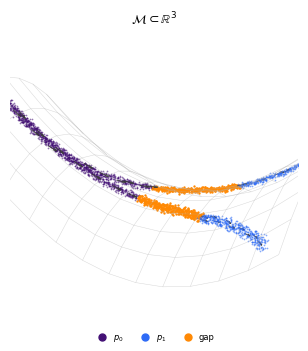

In [2]:
paper.figure5a()

## Learned trajectories (Figure 5b)

Qualitative comparison of trajectories generated from five randomly drawn source cells by seed-0 re-runs of the Table 9 configuration at the 50/50 allocation, identical to the Table 9 records for four of the five arms (the retrained MFM / LAND differs slightly). For FFM with noise, one of the 64 sampled trajectories per cell is shown.

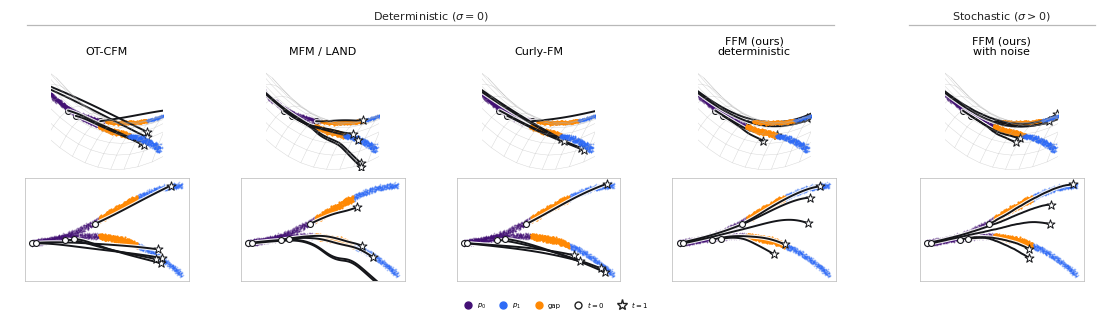

In [3]:
paper.figure5b()

## Fate recall under different allocations (Table 9)

ForkSheet recall under different nominal lower/upper fate allocations. Values are percentages, reported as mean ± population standard deviation over ten seeds; for each method the first row reports lower-arm recall and the second upper-arm recall. Recall is the fraction of an arm's scored cells whose endpoint lies in that arm's region; for FFM with noise it averages over the 64 sampled trajectories of each cell.

In [4]:
paper.table9()

50/50        70/30        40/60  \
Method                    Arm                                                
OT-CFM                    lower arm  69.7 ± 13.2   70.9 ± 8.4   63.4 ± 9.3   
                          upper arm   99.0 ± 2.0   98.9 ± 2.6   99.3 ± 0.9   
MFM / LAND                lower arm   97.5 ± 2.5   96.8 ± 4.0  88.9 ± 12.2   
                          upper arm  79.3 ± 22.3  79.6 ± 18.5   95.8 ± 7.7   
Curly-FM                  lower arm  46.8 ± 16.9   67.2 ± 9.9  33.3 ± 14.4   
                          upper arm  100.0 ± 0.0  100.0 ± 0.0  100.0 ± 0.0   
FFM (ours), deterministic lower arm   92.1 ± 9.5   98.5 ± 1.9   95.3 ± 4.4   
                          upper arm   93.5 ± 7.8   91.7 ± 7.5   95.7 ± 5.5   
FFM (ours), with noise    lower arm   93.9 ± 6.0   97.6 ± 3.2   93.9 ± 5.6   
                          upper arm   95.2 ± 6.7   90.0 ± 7.1  92.2 ± 11.0   

                                           20/80        10/90  
Method                    Arm                                  
OT-CFM                    lower arm  52.1 ± 20.3  22.2 ± 15.8  
                          upper arm   98.3 ± 2.3   98.2 ± 3.7  
MFM / LAND                lower arm  70.8 ± 16.8  56.7 ± 19.6  
                          upper arm  91.9 ± 13.7   97.7 ± 5.2  
Curly-FM                  lower arm  21.3 ± 17.4    0.0 ± 0.0  
                          upper arm  100.0 ± 0.0  100.0 ± 0.0  
FFM (ours), deterministic lower arm   97.0 ± 2.5  74.2 ± 12.4  
                          upper arm  88.2 ± 14.3   95.7 ± 4.7  
FFM (ours), with noise    lower arm   96.1 ± 4.0  73.6 ± 18.7  
                          upper arm  87.6 ± 13.2   95.9 ± 5.9